# Dự báo mực nước hồ Sông Ba Hạ 

**Bài toán trong một câu:** biết mực nước, lượng nước về hồ, lượng nước xả và lượng mưa **đến hiện tại**, hãy đoán mực nước hồ sẽ là bao nhiêu sau 1 giờ, 6 giờ, 1 ngày, 3 ngày, 7 ngày nữa.

**Cách học và thi (giống đi học thật):**
- Mô hình **học** từ dữ liệu 2022–2024 (đề bài đã biết đáp án).
- Rồi **thi** trên năm 2025 (mô hình chưa từng thấy). Điểm thi trên 2025 mới là điểm đáng tin.
- Tuyệt đối không cho mô hình xem trước dữ liệu 2025.

| Từ trong bài | Nghĩa đơn giản |
|---|---|
| Dự báo trước (hạn dự báo) | Dự báo cho thời điểm bao lâu nữa: 1 giờ, 6 giờ, 24 giờ (1 ngày), 72 giờ (3 ngày), 168 giờ (7 ngày) |
| Giữ nguyên | Cách đoán đơn giản nhất: "mực nước mai bằng mực nước hôm nay". Dùng làm **mốc so sánh** |
| Mô hình | Một "công thức" máy tự học từ dữ liệu quá khứ để đoán tương lai |
| Thông tin đầu vào | Các con số mô hình được xem để đoán: mực nước hiện tại, mực nước 1 ngày trước, lượng mưa 3 ngày qua,... |
| Mức thay đổi mực nước | Mực nước sẽ tăng hay giảm bao nhiêu mét so với bây giờ. Mô hình đoán số này rồi cộng vào mực nước hiện tại |
| Sai số | Chênh lệch giữa dự báo và thực đo (mét). Càng nhỏ càng tốt |
| Học thuộc lòng | Mô hình làm bài cũ rất tốt nhưng làm bài mới kém. Ta tránh bằng cách luôn thi trên dữ liệu chưa thấy |

## Bước 1. Chuẩn bị công cụ

In [156]:
import os, copy, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.base import clone

import sbh_prep as P      

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Kiểm tra công cụ tùy chọn
try:
    from xgboost import XGBRegressor; HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    import torch, torch.nn as nn; HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

# ---- Các lựa chọn của bài ----
DATA_PATH = "raw_data_sbh.csv"
FIG_DIR = "figs2"; os.makedirs(FIG_DIR, exist_ok=True)
SEED = 42                  # số cố định để chạy lại ra cùng kết quả
FAST_MODE = False          # True = chạy thử nhanh; False = chạy đầy đủ
DO_TUNING = True         
HORIZONS = list(P.HORIZONS)    # dự báo trước: [1, 6, 24, 72, 168] giờ
if FAST_MODE:
    HORIZONS = [24, 72]

MNC, MNDBT = P.MNC, P.MNDBT    # mực nước chết 101,0 m; mực nước dâng bình thường 105,0 m
BASE = "Giữ nguyên"            # tên của cách đoán đơn giản nhất
GB_NAME = "XGBoost" if HAS_XGB else "HistGB*" 
print("Dự báo trước (giờ):", HORIZONS)


Dự báo trước (giờ): [1, 6, 24, 72, 168]


## Bước 2. Đọc dữ liệu và tạo "bảng đề bài"

**Mục đích:** biến dữ liệu thô thành bảng mà mô hình học được: mỗi hàng là một thời điểm, gồm *thông tin biết được ở thời điểm đó* và *đáp án* (mực nước thực sự sau X giờ).

**Chia dữ liệu:** 2022–2024 để học, 2025 để thi. Cuối phần học bỏ vài giờ để đáp án không "chạm" sang phần thi.

In [157]:
df = P.load_clean(DATA_PATH)       # đọc dữ liệu, bỏ giá trị sai, điền chỗ thiếu ngắn 

datasets = {}                      # datasets[24] = (bảng học 2022–2023, bảng 2024, bảng thi 2025) cho dự báo trước 24 giờ
for hz in HORIZONS:
    datasets[hz] = P.split_by_time(P.make_features(df, hz), hz)

FEATS = P.feature_names(datasets[HORIZONS[0]][0])    # tên các cột "thông tin đầu vào"
hoc, thi = pd.concat(datasets[HORIZONS[0]][:2]), datasets[HORIZONS[0]][2]
print(f"Có {len(FEATS)} thông tin đầu vào cho mỗi thời điểm.")
print(f"Dữ liệu học: {hoc.index.min().date()} → {hoc.index.max().date()}  ({len(hoc)} giờ)")
print(f"Dữ liệu thi: {thi.index.min().date()} → {thi.index.max().date()}  ({len(thi)} giờ)")

Có 47 thông tin đầu vào cho mỗi thời điểm.
Dữ liệu học: 2022-01-08 → 2024-12-31  (25751 giờ)
Dữ liệu thi: 2025-01-01 → 2025-12-31  (8682 giờ)


In [158]:
# Xem thử vài hàng của "bảng đề bài" (dự báo trước 24 giờ)
hz_demo = 24 if 24 in HORIZONS else HORIZONS[0]
xem = datasets[hz_demo][0][["H_now", "H_tl_lag24", "Q_ve_now", "Rain_sum72", "y_level"]].head(5)
xem.columns = ["Mực nước hiện tại", "Mực nước 1 ngày trước", "Lưu lượng về hồ hiện tại", "Mưa 3 ngày qua", f"ĐÁP ÁN: mực nước sau {hz_demo}h"]
xem

,Mực nước hiện tại,Mực nước 1 ngày trước,Lưu lượng về hồ hiện tại,Mưa 3 ngày qua,ĐÁP ÁN: mực nước sau 24h
time,,,,,
2022-01-08 00:00:00,104.29,104.34,200.0,1.95,104.27
2022-01-08 01:00:00,104.29,104.33,195.0,1.89,104.26
2022-01-08 02:00:00,104.29,104.33,195.0,1.86,104.26
2022-01-08 03:00:00,104.29,104.32,180.0,1.83,104.28
2022-01-08 04:00:00,104.29,104.31,180.0,1.80,104.28


## Bước 3. Cách chấm điểm

**Mục đích:** định nghĩa các điểm số để so sánh các mô hình công bằng.

**Hiểu đơn giản:**
- **MAE** (m): trung bình mỗi lần đoán lệch bao nhiêu mét. Dễ hiểu nhất.
- **RMSE** (m): giống MAE nhưng *phạt nặng hơn* những lần lệch lớn (nên lúc lũ hay bị tính nặng).
- **NSE**: điểm tối đa là 1 (đoán hoàn hảo). Bằng 0 nghĩa là chỉ giỏi ngang cách "lúc nào cũng đoán bằng mực nước trung bình". Âm nghĩa là còn tệ hơn.
- **R²**: mức độ đường dự báo "đi cùng chiều" với đường thực đo (1 là cùng chiều hoàn toàn).
- **Lệch TB** (m): dự báo trung bình cao hơn (+) hay thấp hơn (−) thực đo.
- **Cải thiện so với giữ nguyên (%)**: sai số (RMSE) giảm bao nhiêu % so với cách "giữ nguyên mực nước hiện tại". **Số dương = mô hình thắng mốc, số âm = thua mốc.** Đây là điểm quan trọng nhất.

In [159]:
def nse(obs, sim):
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - obs.mean()) ** 2)

def metrics(obs, sim):
    """obs = thực đo, sim = dự báo (cùng độ dài)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    err = sim - obs
    return {"RMSE": np.sqrt(np.mean(err ** 2)),       # sai số, phạt nặng lần lệch lớn
            "MAE": np.mean(np.abs(err)),              # sai số trung bình
            "R2": np.corrcoef(obs, sim)[0, 1] ** 2,   # mức "đi cùng chiều"
            "NSE": nse(obs, sim),                     # điểm tối đa 1
            "Lệch TB": err.mean()}                    # dự báo cao hơn/thấp hơn bao nhiêu

## Bước 4. Mốc so sánh: "Giữ nguyên"

**Mục đích:** tạo cách đoán đơn giản nhất để làm mốc: *mực nước sau X giờ = mực nước bây giờ*.

In [160]:
PRED = {}     # PRED[(tên mô hình, dự báo trước)] = mực nước mô hình dự báo (m) cho năm 2025
OBS = {hz: datasets[hz][2]["y_level"] for hz in HORIZONS}      # mực nước thực đo ở thời điểm cần dự báo (đáp án thi)
MODELS = {}   # lưu các mô hình đã học xong

for hz in HORIZONS:
    PRED[(BASE, hz)] = datasets[hz][2]["H_now"].copy()
print("Xong mốc 'Giữ nguyên'.")

Xong mốc 'Giữ nguyên'.


## Bước 5. Random Forest

In [161]:
def hoc_va_du_bao(ten, tao_mo_hinh):
    """Với mỗi hạn dự báo: cho mô hình học 2022–2024, rồi dự báo 2025."""
    for hz in HORIZONS:
        t0 = time.time()
        tr, va, te = datasets[hz]
        hoc = pd.concat([tr, va])                          # dữ liệu học: 2022–2024
        mo_hinh = tao_mo_hinh()
        mo_hinh.fit(hoc[FEATS], hoc["y_delta"])            # học: từ thông tin đầu vào đoán mức thay đổi mực nước
        thay_doi = mo_hinh.predict(te[FEATS])              # thi: đoán mức thay đổi trong 2025
        PRED[(ten, hz)] = pd.Series(te["H_now"].values + thay_doi, index=te.index)   # cộng vào mực nước hiện tại
        MODELS[(ten, hz)] = mo_hinh
        print(f"{ten:14s} dự báo trước {hz:>3d} giờ: xong ({time.time()-t0:.0f} giây)")

rf_trees = 60 if FAST_MODE else 200
hoc_va_du_bao("Random Forest", lambda: RandomForestRegressor(
    n_estimators=rf_trees, max_depth=12, min_samples_leaf=20, max_features=0.6, n_jobs=-1, random_state=SEED))

Random Forest  dự báo trước   1 giờ: xong (10 giây)
Random Forest  dự báo trước   6 giờ: xong (9 giây)
Random Forest  dự báo trước  24 giờ: xong (9 giây)
Random Forest  dự báo trước  72 giờ: xong (8 giây)
Random Forest  dự báo trước 168 giờ: xong (8 giây)


## Bước 6. XGBoost 

**Mục đích:** thử thêm một mô hình cây mạnh khác để so sánh với rừng cây.

Random Forest để các cây học *song song* rồi lấy trung bình. XGBoost cho cây học *nối tiếp*: cây sau tập trung sửa những chỗ cây trước còn đoán sai, giống học sinh làm bài rồi xem lại câu sai. Thường chính xác hơn, nhưng dễ "học thuộc lòng" hơn nếu cấu hình không cẩn thận.

In [162]:
def tao_gb():
    n = 100 if FAST_MODE else 300
    if HAS_XGB:
        return XGBRegressor(n_estimators=n, max_depth=4, learning_rate=0.05, subsample=0.8,
                            colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=SEED)
    return HistGradientBoostingRegressor(max_iter=n, max_depth=4, learning_rate=0.05, random_state=SEED)

hoc_va_du_bao(GB_NAME, tao_gb)

XGBoost        dự báo trước   1 giờ: xong (1 giây)
XGBoost        dự báo trước   6 giờ: xong (1 giây)
XGBoost        dự báo trước  24 giờ: xong (1 giây)
XGBoost        dự báo trước  72 giờ: xong (1 giây)
XGBoost        dự báo trước 168 giờ: xong (1 giây)


In [ ]:
#Tìm tham số bằng TimeSeriesSplit + RandomizedSearchCV
BEST_PARAMS = {}     # BEST_PARAMS[(tên mô hình, hạn)] = bộ tham số tốt nhất
TEN_RF_T, TEN_GB_T = "Random Forest (tuned)", f"{GB_NAME} (tuned)"

if DO_TUNING:
    N_ITER = 8 if FAST_MODE else 15       # số cấu hình thử cho mỗi hạn
    N_SPLIT = 3                           # số lần chia thời gian

    # --- không gian tìm kiếm ---
    rf_space = {"max_depth": [6, 8, 12, 16], "min_samples_leaf": [5, 10, 20, 50],
                "max_features": [0.3, 0.5, 0.7, 1.0]}
    if HAS_XGB:
        gb_space = {"n_estimators": [200, 300, 500], "max_depth": [3, 4, 5, 6],
                    "learning_rate": [0.02, 0.05, 0.1], "subsample": [0.6, 0.8, 1.0],
                    "colsample_bytree": [0.5, 0.8, 1.0], "min_child_weight": [1, 5, 10]}
    else:
        gb_space = {"max_iter": [200, 300, 500], "max_depth": [3, 4, 5, 6],
                    "learning_rate": [0.02, 0.05, 0.1], "min_samples_leaf": [20, 50, 100]}

    def tim_tham_so(ten, mo_hinh, khong_gian, hz, hoc):
        """Tìm tham số cho một hạn, chỉ dùng dữ liệu học 2022–2024."""
        cv = TimeSeriesSplit(n_splits=N_SPLIT, gap=hz)       # gap = hạn dự báo: đáp án không lọt sang tập kiểm tra
        tk = RandomizedSearchCV(mo_hinh, khong_gian, n_iter=N_ITER, cv=cv,
                                scoring="neg_root_mean_squared_error",
                                random_state=SEED, n_jobs=1, refit=True)
        tk.fit(hoc[FEATS], hoc["y_delta"])
        BEST_PARAMS[(ten, hz)] = tk.best_params_
        print(f"{ten:24s} hạn {hz:>3d}h | RMSE kiểm định chéo (ΔZ) = {-tk.best_score_:.4f} | {tk.best_params_}")
        return tk.best_estimator_

    for hz in HORIZONS:
        t0 = time.time()
        tr, va, te = datasets[hz]
        hoc = pd.concat([tr, va]).sort_index()                # 2022–2024, theo thời gian

        # Random Forest: tìm với 100 cây cho nhanh, rồi học lại với số cây như bản gốc
        rf0 = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED)
        rf_tot = clone(tim_tham_so(TEN_RF_T, rf0, rf_space, hz, hoc)).set_params(n_estimators=rf_trees)
        rf_tot.fit(hoc[FEATS], hoc["y_delta"])
        PRED[(TEN_RF_T, hz)] = pd.Series(te["H_now"].values + rf_tot.predict(te[FEATS]), index=te.index)
        MODELS[(TEN_RF_T, hz)] = rf_tot

        # XGBoost (hoặc HistGB nếu chưa cài xgboost)
        gb0 = tao_gb()
        gb_tot = tim_tham_so(TEN_GB_T, gb0, gb_space, hz, hoc)
        PRED[(TEN_GB_T, hz)] = pd.Series(te["H_now"].values + gb_tot.predict(te[FEATS]), index=te.index)
        MODELS[(TEN_GB_T, hz)] = gb_tot
        print(f"   → hạn {hz}h xong ({time.time()-t0:.0f} giây)\n")
else:
    print("Bỏ qua bước tìm tham số .")

Random Forest (tuned)    hạn   1h | RMSE kiểm định chéo (ΔZ) = 0.0183 | {'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 12}
XGBoost (tuned)          hạn   1h | RMSE kiểm định chéo (ΔZ) = 0.0192 | {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
   → hạn 1h xong (160 giây)

Random Forest (tuned)    hạn   6h | RMSE kiểm định chéo (ΔZ) = 0.0565 | {'min_samples_leaf': 5, 'max_features': 0.7, 'max_depth': 12}
XGBoost (tuned)          hạn   6h | RMSE kiểm định chéo (ΔZ) = 0.0584 | {'subsample': 0.8, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.02, 'colsample_bytree': 0.5}
   → hạn 6h xong (182 giây)

Random Forest (tuned)    hạn  24h | RMSE kiểm định chéo (ΔZ) = 0.1641 | {'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 6}
XGBoost (tuned)          hạn  24h | RMSE kiểm định chéo (ΔZ) = 0.1730 | {'subsample': 0.6, 'n_estimators': 300, 'min_child_weight': 5, 'max_

## Bước 7 LSTM và GRU


 LSTM và GRU là loại mạng thần kinh "có trí nhớ". Khác với mô hình cây (nhìn một bảng số rồi đoán), LSTM/GRU **đọc 72 giờ gần nhất như đọc một cuốn băng theo thứ tự thời gian**, và tự giữ lại những chi tiết quan trọng (ví dụ "2 ngày trước mưa to").

### Chọn thông tin cho mạng thần kinh và đưa về cùng thang đo
Mạng thần kinh học rất kém nếu các con số chênh nhau quá lớn (mực nước ~103, lưu lượng có lúc 16.000). Ta làm hai việc: (1) lấy **logarit** của lưu lượng để lũ lớn không "át" các giá trị khác; (2) đưa mọi cột về cùng thang đo, **chỉ tính thang đo từ dữ liệu học** (nếu tính cả 2025 là xem trước đáp án).

In [164]:
from numpy.lib.stride_tricks import sliding_window_view

DO_LEN = 72     # mạng thần kinh "đọc" 72 giờ gần nhất
COT_DL = ["H_tl", "logQve", "logQx", "Rain", "SoilM", "Humid", "N_cxm",
          "hour_sin", "hour_cos", "month_sin", "month_cos", "is_flood"]

dl = pd.DataFrame(index=df.index)
dl["H_tl"] = df["H_tl"]
dl["logQve"] = np.log1p(df["Q_ve"]); dl["logQx"] = np.log1p(df["Sigma_Qx"])      # logarit lưu lượng
dl["Rain"], dl["SoilM"], dl["Humid"], dl["N_cxm"] = df["Rain"], df["SoilM"], df["Humid"], df["N_cxm"]
dl["hour_sin"] = np.sin(2 * np.pi * df.index.hour / 24);  dl["hour_cos"] = np.cos(2 * np.pi * df.index.hour / 24)    # giờ trong ngày
dl["month_sin"] = np.sin(2 * np.pi * df.index.month / 12); dl["month_cos"] = np.cos(2 * np.pi * df.index.month / 12)  # tháng trong năm
dl["is_flood"] = df["is_flood"]
dl = dl[COT_DL]

t_tr, t_va = pd.Timestamp(P.TRAIN_END), pd.Timestamp(P.VAL_END)
tb, do_lech = dl[dl.index <= t_tr].mean(), dl[dl.index <= t_tr].std()     # thang đo: chỉ tính từ dữ liệu học
Xs = ((dl - tb) / do_lech).values.astype("float32")
print("Đã chuẩn hóa", Xs.shape[1], "cột thông tin cho", Xs.shape[0], "giờ.")

Đã chuẩn hóa 12 cột thông tin cho 35064 giờ.


### Cắt dữ liệu thành các "cuốn băng 72 giờ" và chia học/thi
Mỗi mẫu gồm: 72 giờ gần nhất (đề) và mức thay đổi mực nước sau 1, 6, 24, 72, 168 giờ (đáp án). Những đáp án nằm sau mốc kết thúc của phần học bị **che đi** để mô hình không nhìn thấy trước.

In [165]:
times = df.index.values
H = df["H_tl"].values
n = len(Xs)
ends = np.arange(DO_LEN - 1, n)                                       # giờ cuối của mỗi cuốn băng
hang_ok = np.isfinite(Xs).all(axis=1)
dem_loi = np.concatenate([[0], np.cumsum(~hang_ok)])
bang_ok = (dem_loi[ends + 1] - dem_loi[ends + 1 - DO_LEN]) == 0       # cuốn băng không có chỗ trống

Y = np.full((len(ends), len(HORIZONS)), np.nan)                       # đáp án: mức thay đổi mực nước
T_dap_an = np.full((len(ends), len(HORIZONS)), np.datetime64("NaT"), dtype="datetime64[ns]")
for j, hz in enumerate(HORIZONS):
    ok = ends + hz < n
    Y[ok, j] = H[ends[ok] + hz] - H[ends[ok]]
    T_dap_an[ok, j] = times[ends[ok] + hz]

t0s = times[ends]
tap = np.where(t0s <= np.datetime64(t_tr), 0, np.where(t0s <= np.datetime64(t_va), 1, 2))   # 0: học, 1: kiểm tra, 2: thi (2025)
for k, moc_cuoi in [(0, t_tr), (1, t_va)]:                            # che đáp án vượt khỏi phần học
    Y[(tap == k)[:, None] & (T_dap_an > np.datetime64(moc_cuoi))] = np.nan

giu = bang_ok & np.isfinite(Y).any(axis=1)
W = np.ascontiguousarray(np.swapaxes(sliding_window_view(Xs, DO_LEN, axis=0), 1, 2))

def lay_tap(k):
    idx = np.where(giu & (tap == k))[0]
    return W[idx], Y[idx], idx

Xtr, Ytr, itr = lay_tap(0); Xva, Yva, iva = lay_tap(1); Xte, Yte, ite = lay_tap(2)
y_tb, y_dl = np.nanmean(Ytr, axis=0), np.nanstd(Ytr, axis=0)          # đưa đáp án về thang đo của phần học
print("Số mẫu học / kiểm tra / thi:", len(Xtr), len(Xva), len(Xte))

Số mẫu học / kiểm tra / thi: 17367 8468 8686


### Định nghĩa mạng thần kinh và cách học
- Mạng đọc 72 giờ rồi đưa ra **5 đáp án cùng lúc** (cho 5 hạn dự báo).
- **Dừng sớm:** mỗi vòng học, ta kiểm tra bằng năm 2024. Nếu điểm kiểm tra không cải thiện sau vài vòng thì dừng, để tránh "học thuộc lòng". Mạng tốt nhất được giữ lại.
- Ô này chỉ *định nghĩa* các hàm, chưa học gì.

In [179]:
if HAS_TORCH:
    THIET_BI = "cuda" if torch.cuda.is_available() else "cpu"
    AN, TANG, BO_BOT = 32, 1, 0.3          # mạng nhỏ hơn, dropout cao hơn để đỡ học thuộc lòng
    SO_VONG, KIEN_NHAN, LO, TOC_DO = (4, 2, 256, 3e-4) if FAST_MODE else (40, 6, 256, 3e-4)
    N_SEEDS = 2 if FAST_MODE else 5        # số lần học lại với các seed khác nhau
    SEEDS = [SEED + 17 * k for k in range(N_SEEDS)]

    class MangDuBao(nn.Module):
        """Mạng đọc chuỗi 72 giờ (LSTM hoặc GRU) rồi đưa ra mức thay đổi mực nước cho mọi hạn."""
        def __init__(self, so_cot, an, so_dau_ra, loai="LSTM", tang=2, bo_bot=0.2):
            super().__init__()
            lop = nn.LSTM if loai == "LSTM" else nn.GRU
            # nn.LSTM/GRU chỉ áp dụng dropout giữa các tầng; với 1 tầng thì đặt 0 để khỏi bị cảnh báo
            self.doc = lop(so_cot, an, num_layers=tang, batch_first=True,
                           dropout=bo_bot if tang > 1 else 0.0)
            self.bo_bot = nn.Dropout(bo_bot)
            self.dau_ra = nn.Sequential(nn.Linear(an, an), nn.ReLU(), nn.Linear(an, so_dau_ra))
        def forward(self, x):
            out, _ = self.doc(x)
            return self.dau_ra(self.bo_bot(out[:, -1, :]))   # dùng "ghi nhớ" sau khi đọc xong đến giờ cuối

    def sai_so_co_mat_na(du_doan, dap_an):
        """Sai số bình phương, bỏ qua những ô chưa có đáp án thật."""
        co = ~torch.isnan(dap_an)
        d = torch.where(co, du_doan - torch.nan_to_num(dap_an), torch.zeros_like(du_doan))
        return (d ** 2).sum() / co.sum().clamp(min=1)

    def tensor(a): return torch.tensor(a, dtype=torch.float32)
    Xtr_t, Ytr_t = tensor(Xtr), tensor((Ytr - y_tb) / y_dl)
    Xva_t, Yva_t = tensor(Xva), tensor((Yva - y_tb) / y_dl)
    X_hoc = torch.cat([Xtr_t, Xva_t])      # dữ liệu 2022–2024 
    Y_hoc = torch.cat([Ytr_t, Yva_t])

    def du_doan_thang_do(mo_hinh, X, bs=1024):
        mo_hinh.eval(); kq = []
        with torch.no_grad():
            for i in range(0, len(X), bs):
                kq.append(mo_hinh(tensor(X[i:i + bs]).to(THIET_BI)).cpu().numpy())
        return np.concatenate(kq)

    def huan_luyen(loai, seed, X_t, Y_t, so_vong, X_v=None, Y_v=None, in_log=False):
        """Có X_v, Y_v: dừng sớm, trả về (mạng tốt nhất, vòng tốt nhất).
        Không có: học đúng `so_vong` vòng, trả về (mạng, so_vong)."""
        torch.manual_seed(seed); np.random.seed(seed)
        mo_hinh = MangDuBao(len(COT_DL), AN, len(HORIZONS), loai, TANG, BO_BOT).to(THIET_BI)
        opt = torch.optim.Adam(mo_hinh.parameters(), lr=TOC_DO, weight_decay=1e-5)
        tot_nhat, trang_thai, vong_tot, cho = np.inf, None, so_vong, 0
        for vong in range(1, so_vong + 1):
            mo_hinh.train(); thu_tu = torch.randperm(len(X_t)); tong = 0.0
            for i in range(0, len(thu_tu), LO):
                b = thu_tu[i:i + LO]
                opt.zero_grad()
                loss = sai_so_co_mat_na(mo_hinh(X_t[b].to(THIET_BI)), Y_t[b].to(THIET_BI))
                loss.backward(); nn.utils.clip_grad_norm_(mo_hinh.parameters(), 1.0); opt.step()
                tong += loss.item() * len(b)
            if X_v is not None:
                mo_hinh.eval()
                with torch.no_grad():
                    kiem_tra = np.mean([sai_so_co_mat_na(mo_hinh(X_v[i:i + 1024].to(THIET_BI)),
                                                         Y_v[i:i + 1024].to(THIET_BI)).item()
                                        for i in range(0, len(X_v), 1024)])
                if in_log:
                    print(f"[{loai}] Epoch {vong:>2d}: "f"Training Loss = {tong/len(X_t):.4f} | "f"Validation Loss (2024) = {kiem_tra:.4f}"
    )
                if kiem_tra < tot_nhat - 1e-4:
                    tot_nhat, trang_thai, vong_tot, cho = kiem_tra, copy.deepcopy(mo_hinh.state_dict()), vong, 0
                else:
                    cho += 1
                    if cho >= KIEN_NHAN:
                        if in_log: print("  → dừng sớm (kiểm tra không cải thiện thêm)")
                        break
        if trang_thai is not None:
            mo_hinh.load_state_dict(trang_thai)
        return mo_hinh, vong_tot

    DU_DOAN_SEED = {}      # DU_DOAN_SEED[loai] = mảng (số seed, số mẫu thi, số hạn), để xem độ dao động

    def thi_mang(loai):
        # Pha 1: chọn số vòng học (học 2022–2023, kiểm tra 2024), mỗi seed một lần
        vong_tot = [huan_luyen(loai, s, Xtr_t, Ytr_t, SO_VONG, Xva_t, Yva_t, in_log=(k == 0))[1]
                    for k, s in enumerate(SEEDS)]
        n_vong = max(1, int(round(np.median(vong_tot))))
        print(f"[{loai}] vòng tốt nhất theo từng seed: {vong_tot} → dùng {n_vong} vòng cho pha 2")

        # Pha 2: học lại trên 2022–2024 với đúng n_vong vòng, nhiều seed, lấy trung bình dự báo
        chi_so_gio = pd.DatetimeIndex(times[ends[ite]])
        ds = []
        for s in SEEDS:
            mo_hinh, _ = huan_luyen(loai, s, X_hoc, Y_hoc, n_vong)
            ds.append(du_doan_thang_do(mo_hinh, Xte) * y_dl + y_tb)        # trả về mét
            MODELS[(loai, s)] = mo_hinh
        ds = np.stack(ds)
        DU_DOAN_SEED[loai] = ds
        tb = ds.mean(axis=0)                                               # trung bình các seed
        for j, hz in enumerate(HORIZONS):
            PRED[(loai, hz)] = pd.Series(H[ends[ite]] + tb[:, j], index=chi_so_gio)

    print("Đã định nghĩa mạng. Thiết bị tính toán:", THIET_BI, f"| số seed: {N_SEEDS}")
else:
    print("Bỏ qua phần LSTM/GRU (chưa cài torch)...")

Đã định nghĩa mạng. Thiết bị tính toán: cpu | số seed: 5


### Cho LSTM học và thi

In [180]:
if HAS_TORCH:
    t0 = time.time(); thi_mang("LSTM"); print(f"LSTM xong ({time.time()-t0:.0f} giây)")

[LSTM] Epoch  1: Training Loss = 0.9862 | Validation Loss (2024) = 0.5508
[LSTM] Epoch  2: Training Loss = 0.9319 | Validation Loss (2024) = 0.5421
[LSTM] Epoch  3: Training Loss = 0.8512 | Validation Loss (2024) = 0.5353
[LSTM] Epoch  4: Training Loss = 0.7840 | Validation Loss (2024) = 0.5792
[LSTM] Epoch  5: Training Loss = 0.7366 | Validation Loss (2024) = 0.6199
[LSTM] Epoch  6: Training Loss = 0.7013 | Validation Loss (2024) = 0.6572
[LSTM] Epoch  7: Training Loss = 0.6744 | Validation Loss (2024) = 0.6770
[LSTM] Epoch  8: Training Loss = 0.6469 | Validation Loss (2024) = 0.6852
[LSTM] Epoch  9: Training Loss = 0.6332 | Validation Loss (2024) = 0.7004
  → dừng sớm (kiểm tra không cải thiện thêm)
[LSTM] vòng tốt nhất theo từng seed: [3, 2, 2, 1, 2] → dùng 2 vòng cho pha 2
LSTM xong (82 giây)


### Cho GRU học và thi
GRU là phiên bản gọn hơn của LSTM (ít bộ phận hơn, thường học nhanh hơn).

In [181]:
if HAS_TORCH:
    t0 = time.time(); thi_mang("GRU"); print(f"GRU xong ({time.time()-t0:.0f} giây)")

[GRU] Epoch  1: Training Loss = 0.9822 | Validation Loss (2024) = 0.5418
[GRU] Epoch  2: Training Loss = 0.9238 | Validation Loss (2024) = 0.5432
[GRU] Epoch  3: Training Loss = 0.8574 | Validation Loss (2024) = 0.5795
[GRU] Epoch  4: Training Loss = 0.7971 | Validation Loss (2024) = 0.6220
[GRU] Epoch  5: Training Loss = 0.7584 | Validation Loss (2024) = 0.6291
[GRU] Epoch  6: Training Loss = 0.7297 | Validation Loss (2024) = 0.6489
[GRU] Epoch  7: Training Loss = 0.7021 | Validation Loss (2024) = 0.6453
  → dừng sớm (kiểm tra không cải thiện thêm)
[GRU] vòng tốt nhất theo từng seed: [1, 3, 2, 2, 2] → dùng 2 vòng cho pha 2
GRU xong (187 giây)


## Bước 8. Bảng điểm so sánh trên năm thi 2025



In [169]:
THU_TU = [m for m in [BASE, "Random Forest", TEN_RF_T, GB_NAME, TEN_GB_T, "LSTM", "GRU"]
          if any(k[0] == m for k in PRED)]

def lap_bang(loc=None):
    """Bảng điểm. `loc` là hàm lọc thời điểm (ví dụ chỉ mùa lũ)."""
    rows = []
    for hz in HORIZONS:
        chung = OBS[hz].dropna().index
        for m in THU_TU: chung = chung.intersection(PRED[(m, hz)].dropna().index)
        if loc is not None: chung = chung[loc(chung)]
        if len(chung) < 30: continue
        obs = OBS[hz].loc[chung]
        moc = metrics(obs, PRED[(BASE, hz)].loc[chung])["RMSE"]
        for m in THU_TU:
            r = metrics(obs, PRED[(m, hz)].loc[chung])
            r.update({"Dự báo trước (giờ)": hz, "Mô hình": m, "Số mẫu": len(chung),
                      "Cải thiện so với giữ nguyên (%)": 100 * (1 - r["RMSE"] / moc)})
            rows.append(r)
    cot = ["Dự báo trước (giờ)", "Mô hình", "Số mẫu", "RMSE", "MAE", "R2", "NSE", "Lệch TB", "Cải thiện so với giữ nguyên (%)"]
    return pd.DataFrame(rows)[cot]

BANG = lap_bang()
print(BANG.round(3).to_string(index=False))
BANG.round(4).to_csv("ket_qua_so_sanh.csv", index=False, encoding="utf-8-sig")

 Dự báo trước (giờ)               Mô hình  Số mẫu  RMSE   MAE    R2   NSE  Lệch TB  Cải thiện so với giữ nguyên (%)
                  1            Giữ nguyên    8682 0.038 0.008 0.998 0.998    0.000                            0.000
                  1         Random Forest    8682 0.036 0.006 0.999 0.999   -0.000                            5.548
                  1 Random Forest (tuned)    8682 0.036 0.006 0.998 0.998   -0.000                            5.113
                  1               XGBoost    8682 0.056 0.008 0.996 0.996   -0.002                          -47.967
                  1       XGBoost (tuned)    8682 0.038 0.007 0.998 0.998   -0.001                           -0.613
                  1                  LSTM    8682 0.038 0.009 0.998 0.998   -0.001                            0.542
                  1                   GRU    8682 0.037 0.008 0.998 0.998   -0.001                            0.686
                  6            Giữ nguyên    8676 0.102 0.039 0.988 0.98

In [170]:
# Mô hình tốt nhất (RMSE nhỏ nhất) ở từng hạn dự báo
tot = BANG.loc[BANG.groupby("Dự báo trước (giờ)")["RMSE"].idxmin(),
               ["Dự báo trước (giờ)", "Mô hình", "RMSE", "NSE", "Cải thiện so với giữ nguyên (%)"]]
print(tot.round(3).to_string(index=False))

 Dự báo trước (giờ)               Mô hình  RMSE   NSE  Cải thiện so với giữ nguyên (%)
                  1         Random Forest 0.036 0.999                            5.548
                  6 Random Forest (tuned) 0.084 0.992                           17.764
                 24         Random Forest 0.241 0.932                            7.775
                 72       XGBoost (tuned) 0.523 0.674                            7.329
                168 Random Forest (tuned) 0.764 0.293                           11.371


## Bước 9. Vẽ biểu đồ

### 9a. Đường thực đo và đường dự báo
**Mục đích:** nhìn trực quan mô hình bám sát thực tế đến đâu.
**Bạn sẽ thấy:** đường đen là thực đo; các đường màu là dự báo; đường đỏ chấm là MNDBT (105 m). Cột bên trái là cả năm 2025, cột bên phải phóng to quanh đỉnh lũ. Hãy chú ý: mô hình thường **bám theo chậm** khi mực nước thay đổi đột ngột.

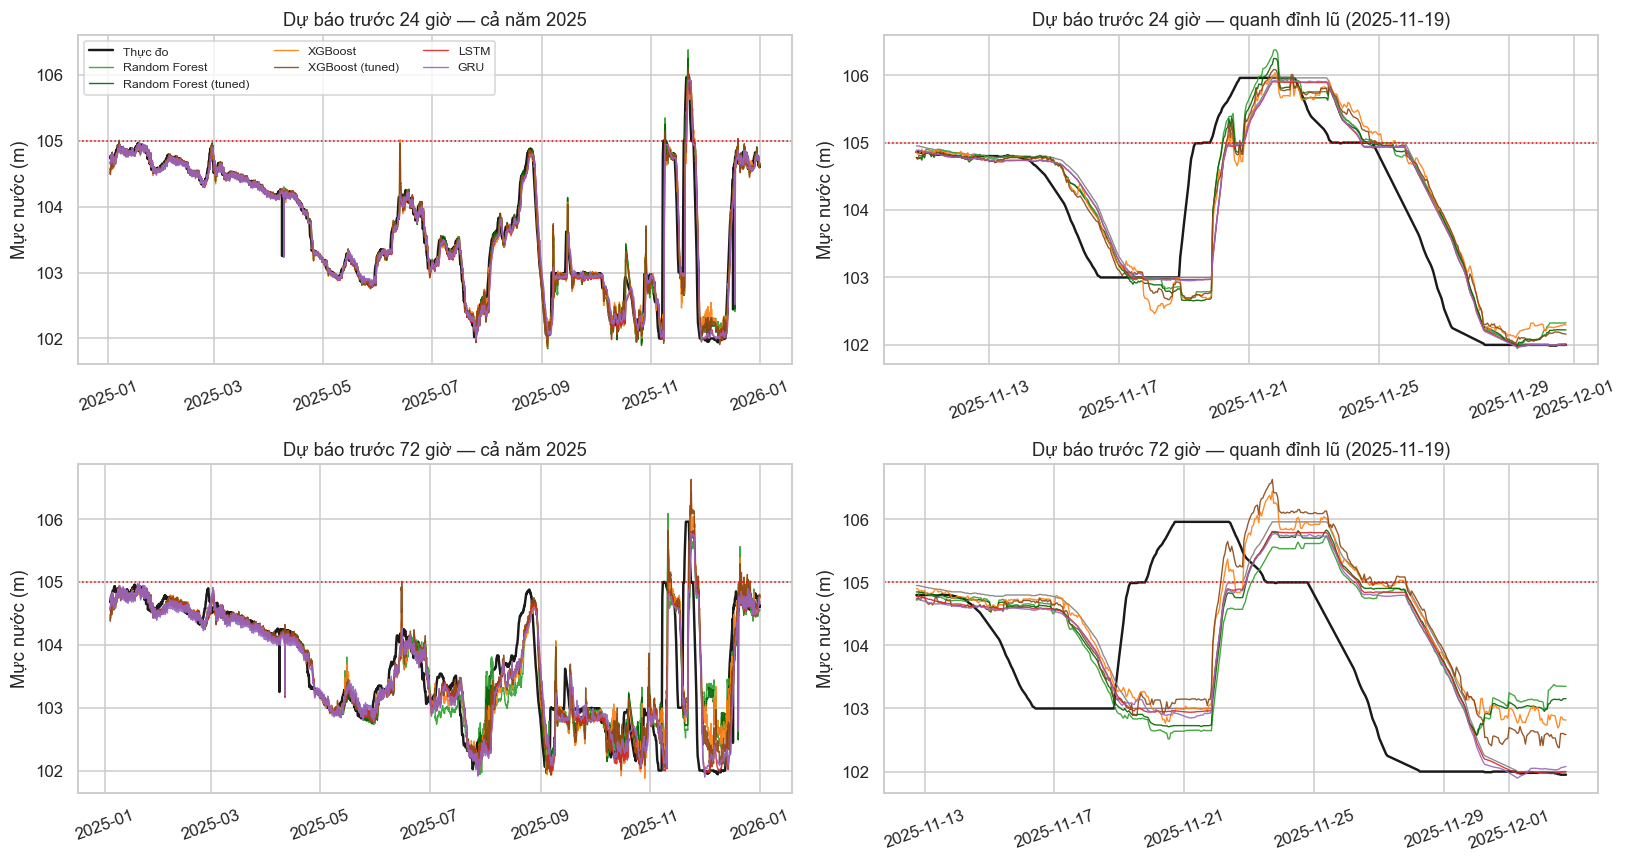

In [173]:
MAU = {BASE: "gray", "Random Forest": "tab:green", TEN_RF_T: "darkgreen",
       GB_NAME: "tab:orange", TEN_GB_T: "saddlebrown",
       "LSTM": "tab:red", "GRU": "tab:purple"}
dinh_lu = df.loc["2025", "Q_ve"].idxmax()                                     # ngày lưu lượng về hồ lớn nhất 2025
phong_to = (dinh_lu - pd.Timedelta(days=10), dinh_lu + pd.Timedelta(days=10))
ve_hz = [h for h in (24, 72) if h in HORIZONS] or HORIZONS[-2:]

fig, axes = plt.subplots(len(ve_hz), 2, figsize=(15, 4 * len(ve_hz)), squeeze=False)
for r, hz in enumerate(ve_hz):
    obs = OBS[hz]
    for c, (a, b) in enumerate([(obs.index.min(), obs.index.max()), phong_to]):
        ax = axes[r, c]; o = obs.loc[a:b]
        ax.plot(o.index + pd.Timedelta(hours=hz), o.values, "k", lw=1.6, label="Thực đo")     # vẽ theo thời điểm được dự báo
        for m in THU_TU:
            if m == BASE and c == 0: continue
            p = PRED[(m, hz)].loc[a:b]
            ax.plot(p.index + pd.Timedelta(hours=hz), p.values, color=MAU[m], lw=0.9, alpha=0.9, label=m)
        ax.axhline(MNDBT, color="red", ls=":", lw=1)
        ax.set_title(f"Dự báo trước {hz} giờ — " + ("cả năm 2025" if c == 0 else f"quanh đỉnh lũ ({dinh_lu.date()})"))
        ax.set_ylabel("Mực nước (m)"); ax.tick_params(axis="x", rotation=20)
        if r == 0 and c == 0: ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/kq1_thucdo_dubao.png"); plt.show()

### 9b. Sai số thay đổi thế nào khi dự báo càng xa
**Bạn sẽ thấy:** dự báo càng xa thì sai số càng lớn (hiển nhiên), và điểm NSE giảm. Hãy xem từ hạn nào mô hình bắt đầu **thắng rõ rệt** đường "giữ nguyên".

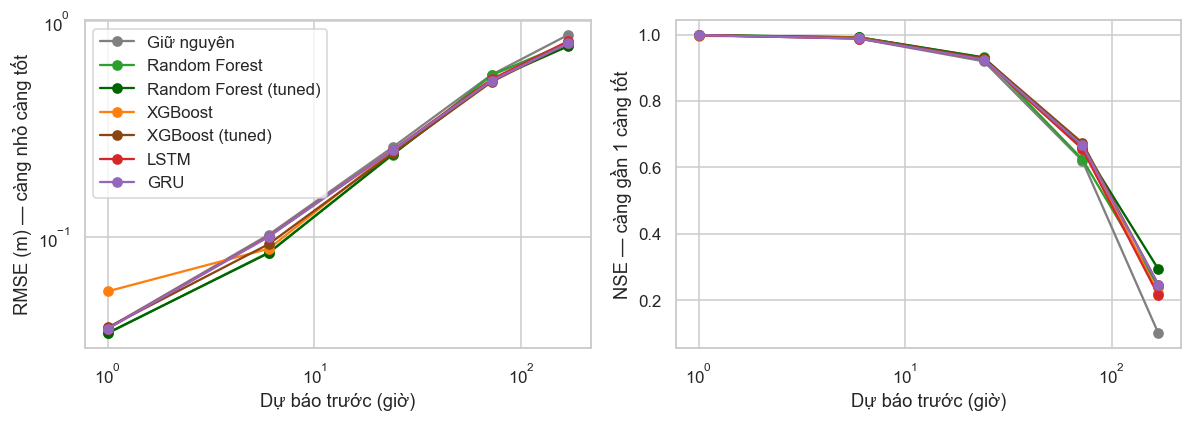

In [174]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m in THU_TU:
    t = BANG[BANG["Mô hình"] == m]
    axes[0].plot(t["Dự báo trước (giờ)"], t["RMSE"], "o-", color=MAU[m], label=m)
    axes[1].plot(t["Dự báo trước (giờ)"], t["NSE"], "o-", color=MAU[m], label=m)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("Dự báo trước (giờ)"); axes[0].set_ylabel("RMSE (m) — càng nhỏ càng tốt"); axes[0].legend()
axes[1].set_xscale("log"); axes[1].set_xlabel("Dự báo trước (giờ)"); axes[1].set_ylabel("NSE — càng gần 1 càng tốt")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/kq2_sai_so_theo_han.png"); plt.show()

## Bước 10. Mô hình sai ở đâu, khi nào?

### 10a. Mùa lũ và mùa kiệt
Mùa lũ tính từ tháng 9 đến 12 (từ phân tích Phần 1). Thường mô hình dự báo tốt ở mùa kiệt (nước biến đổi chậm) và kém hơn ở mùa lũ (nước biến đổi nhanh, phụ thuộc mưa tương lai mà mô hình không biết).

In [175]:
ds = [h for h in [24, 72, 168] if h in HORIZONS]
mua = []
for ten, loc in [("Mùa lũ (tháng 9–12)", lambda i: np.isin(i.month, P.FLOOD_MONTHS)),
                 ("Mùa kiệt (tháng 1–8)", lambda i: ~np.isin(i.month, P.FLOOD_MONTHS))]:
    t = lap_bang(loc); t.insert(0, "Mùa", ten); mua.append(t)
mua = pd.concat(mua)
print(mua[mua["Dự báo trước (giờ)"].isin(ds)][["Mùa", "Dự báo trước (giờ)", "Mô hình", "RMSE", "MAE", "NSE",
                                                "Cải thiện so với giữ nguyên (%)"]].round(3).to_string(index=False))

                 Mùa  Dự báo trước (giờ)               Mô hình  RMSE   MAE    NSE  Cải thiện so với giữ nguyên (%)
 Mùa lũ (tháng 9–12)                  24            Giữ nguyên 0.427 0.197  0.843                            0.000
 Mùa lũ (tháng 9–12)                  24         Random Forest 0.401 0.209  0.861                            5.978
 Mùa lũ (tháng 9–12)                  24 Random Forest (tuned) 0.403 0.200  0.860                            5.646
 Mùa lũ (tháng 9–12)                  24               XGBoost 0.419 0.223  0.848                            1.737
 Mùa lũ (tháng 9–12)                  24       XGBoost (tuned) 0.408 0.209  0.856                            4.304
 Mùa lũ (tháng 9–12)                  24                  LSTM 0.413 0.197  0.853                            3.261
 Mùa lũ (tháng 9–12)                  24                   GRU 0.412 0.198  0.853                            3.385
 Mùa lũ (tháng 9–12)                  72            Giữ nguyên 0.903 0.519  0.29

### 10b. Sai ở mức nước nào?
Chia mực nước thực đo thành các nhóm (dưới 102 m, 102–103 m, ...) rồi xem sai số từng nhóm. Nhóm nào sai nhiều là nơi mô hình yếu. Biểu đồ bên phải cho thấy sai số dư/thiếu: hộp lệch về phía dương = hay đoán cao hơn thực tế.

Sai số RMSE theo mức nước thực đo (dự báo trước 72 giờ):
         Giữ nguyên  Random Forest  Random Forest (tuned)  XGBoost  XGBoost (tuned)   LSTM    GRU
y_level                                                                                          
<102          0.616          1.108                  1.072    0.904            0.750  0.589  0.584
102–103       0.560          0.481                  0.471    0.512            0.501  0.502  0.492
103–104       0.466          0.446                  0.388    0.402            0.411  0.441  0.435
104–105       0.516          0.441                  0.421    0.431            0.471  0.498  0.484
>105          2.198          2.507                  2.407    2.185            2.077  2.238  2.269


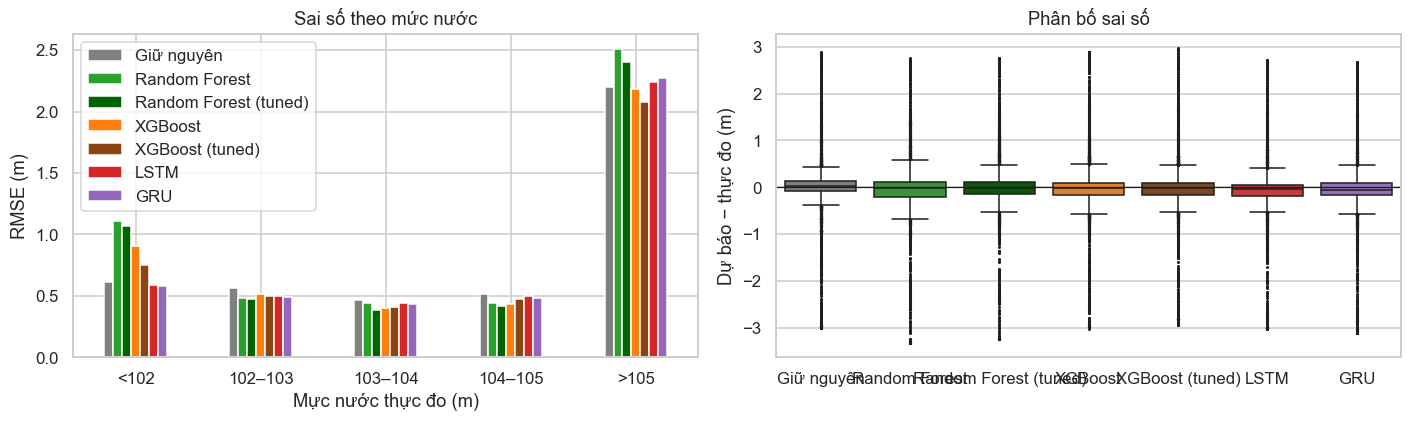

In [176]:
hz_ps = ve_hz[-1]
chung = OBS[hz_ps].dropna().index
for m in THU_TU: chung = chung.intersection(PRED[(m, hz_ps)].dropna().index)
obs = OBS[hz_ps].loc[chung]
nhom = pd.cut(obs, [0, 102, 103, 104, 105, 200], labels=["<102", "102–103", "103–104", "104–105", ">105"])
rmse_nhom = pd.DataFrame({m: (PRED[(m, hz_ps)].loc[chung] - obs).groupby(nhom).apply(lambda e: np.sqrt((e ** 2).mean()))
                          for m in THU_TU})
print(f"Sai số RMSE theo mức nước thực đo (dự báo trước {hz_ps} giờ):"); print(rmse_nhom.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rmse_nhom.plot(kind="bar", ax=axes[0], color=[MAU[m] for m in THU_TU], rot=0)
axes[0].set_xlabel("Mực nước thực đo (m)"); axes[0].set_ylabel("RMSE (m)"); axes[0].set_title("Sai số theo mức nước")
du = pd.DataFrame({m: PRED[(m, hz_ps)].loc[chung] - obs for m in THU_TU})
sns.boxplot(data=du, ax=axes[1], palette=[MAU[m] for m in THU_TU], fliersize=1)
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_ylabel("Dự báo − thực đo (m)"); axes[1].set_title("Phân bố sai số")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/kq3_sai_so_theo_muc_nuoc.png"); plt.show()

### 10c. Dự báo có vi phạm giới hạn vận hành, và có báo động đúng không?
- Mực nước phải nằm trong khoảng **MNC (101 m) – MNDBT (105 m)**. Ta xem dự báo có "vượt rào" không. Lũ lớn có thể làm mực nước thật vượt 105 m tạm thời, đó không phải lỗi dữ liệu.
- **Báo động:** thử đặt ngưỡng cảnh báo "mực nước từ 104,5 m trở lên" (gần MNDBT) và "từ 101,5 m trở xuống" (gần MNC), xem mô hình **phát hiện đúng** bao nhiêu % lần xảy ra và **báo nhầm** bao nhiêu %. Ngưỡng 104,5 và 101,5 là ví dụ, có thể đổi theo yêu cầu vận hành.

In [177]:
print(f"Tỉ lệ dự báo vượt giới hạn (dự báo trước {hz_ps} giờ):")
for m in THU_TU:
    p = PRED[(m, hz_ps)].loc[chung]
    print(f"  {m:14s} dưới MNC: {(p < MNC).mean():.2%} | trên MNDBT: {(p > MNDBT).mean():.2%}   (thực tế trên MNDBT: {(obs > MNDBT).mean():.2%})")

NGUONG_CAO, NGUONG_THAP = 104.5, 101.5
for ten, nguong, so_sanh in [(f"mực nước CAO (≥ {NGUONG_CAO} m)", NGUONG_CAO, np.greater_equal),
                             (f"mực nước THẤP (≤ {NGUONG_THAP} m)", NGUONG_THAP, np.less_equal)]:
    xay_ra = so_sanh(obs, nguong)
    print(f"\nCảnh báo {ten}: số giờ thực tế xảy ra = {int(xay_ra.sum())}")
    if xay_ra.sum() < 5:
        print("  (quá ít để đánh giá)"); continue
    for m in THU_TU:
        bao = so_sanh(PRED[(m, hz_ps)].loc[chung], nguong)
        dung, nham, sot = (bao & xay_ra).sum(), (bao & ~xay_ra).sum(), (~bao & xay_ra).sum()
        print(f"  {m:14s} phát hiện đúng: {dung/(dung+sot):.1%} | trong số lần báo, báo nhầm: {nham/max(dung+nham,1):.1%}")

Tỉ lệ dự báo vượt giới hạn (dự báo trước 72 giờ):
  Giữ nguyên     dưới MNC: 0.00% | trên MNDBT: 1.03%   (thực tế trên MNDBT: 1.03%)
  Random Forest  dưới MNC: 0.00% | trên MNDBT: 1.13%   (thực tế trên MNDBT: 1.03%)
  Random Forest (tuned) dưới MNC: 0.00% | trên MNDBT: 1.23%   (thực tế trên MNDBT: 1.03%)
  XGBoost        dưới MNC: 0.00% | trên MNDBT: 1.63%   (thực tế trên MNDBT: 1.03%)
  XGBoost (tuned) dưới MNC: 0.00% | trên MNDBT: 2.21%   (thực tế trên MNDBT: 1.03%)
  LSTM           dưới MNC: 0.00% | trên MNDBT: 0.96%   (thực tế trên MNDBT: 1.03%)
  GRU            dưới MNC: 0.00% | trên MNDBT: 0.94%   (thực tế trên MNDBT: 1.03%)

Cảnh báo mực nước CAO (≥ 104.5 m): số giờ thực tế xảy ra = 2220
  Giữ nguyên     phát hiện đúng: 81.5% | trong số lần báo, báo nhầm: 18.5%
  Random Forest  phát hiện đúng: 70.6% | trong số lần báo, báo nhầm: 13.8%
  Random Forest (tuned) phát hiện đúng: 75.5% | trong số lần báo, báo nhầm: 13.2%
  XGBoost        phát hiện đúng: 75.1% | trong số lần báo, báo n

## Bước 11. Thông tin nào quan trọng với mô hình?
Random Forest tự cho biết nó dựa nhiều nhất vào thông tin nào. Thanh càng dài càng quan trọng.

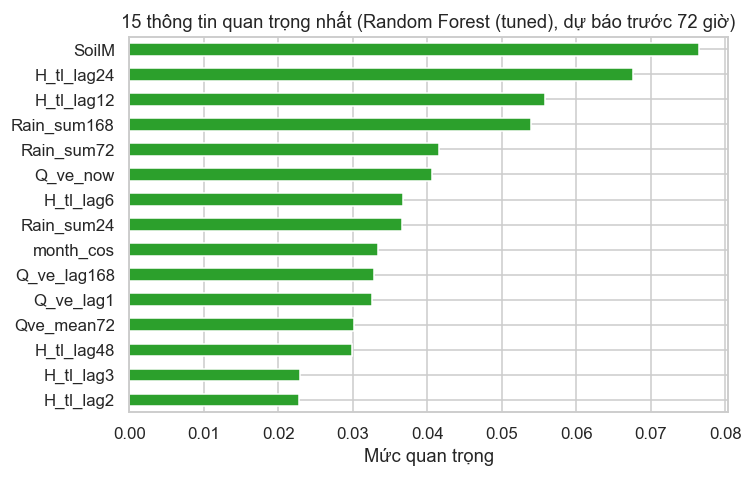

In [178]:
hz_dk = 72 if 72 in HORIZONS else HORIZONS[-1]
ten_rf = TEN_RF_T if (TEN_RF_T, hz_dk) in MODELS else "Random Forest"
rf_tot = MODELS[(ten_rf, hz_dk)]
quan_trong = pd.Series(rf_tot.feature_importances_, index=FEATS).sort_values(ascending=False).head(15)
plt.figure(figsize=(7, 4.5)); quan_trong[::-1].plot(kind="barh", color="tab:green")
plt.xlabel("Mức quan trọng"); plt.title(f"15 thông tin quan trọng nhất ({ten_rf}, dự báo trước {hz_dk} giờ)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/kq4_thong_tin_quan_trong.png"); plt.show()